In [16]:
%pip install transformers torch accelerate sentencepiece safetensors


[notice] A new release of pip available: 22.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


라이브러리 설치 상태 확인

In [17]:
# Transformers 라이브러리 불러오기
import transformers

# PyTorch 라이브러리 불러오기
import torch

# 설치된 라이브러리 버전 출력
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

# GPU 사용 가능 여부 확인
print("GPU 사용 가능:", torch.cuda.is_available())

Transformers: 4.57.6
PyTorch: 2.14.1+cpu
GPU 사용 가능: False


토크나이저 실습

In [18]:
# Hugging Face 토크나이저 불러오기
from transformers import AutoTokenizer

# CPU 실습용 소형 모델 지정
model_name = "distilgpt2"

# 모델에 맞는 토크나이저 다운로드 및 로딩
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 실습할 문장
text = "Hello, robot!"

# 문장을 토큰 ID로 변환
token_ids = tokenizer.encode(text)

# 토큰 ID 출력
print("토큰 ID:", token_ids)

# 토큰 ID를 토큰 문자열로 변환
print("토큰:", tokenizer.convert_ids_to_tokens(token_ids))

# 토큰 개수 출력
print("토큰 개수:", len(token_ids))

# 토큰 ID를 다시 문장으로 복원
print("복원 문장:", tokenizer.decode(token_ids))

토큰 ID: [15496, 11, 9379, 0]
토큰: ['Hello', ',', 'Ġrobot', '!']
토큰 개수: 4
복원 문장: Hello, robot!


토크나이저 결과 비교

In [19]:
# 비교할 문장 목록
sentences = [
    "Hello",
    "Hello, robot!",
    "Artificial intelligence is changing robotics.",
    "안녕하세요. 로봇공학을 공부합니다."
]

# 문장별 토큰 개수 비교
for sentence in sentences:

    # 문장을 토큰 ID로 변환
    ids = tokenizer.encode(sentence)

    # 문장과 토큰 개수 출력
    print("문장:", sentence)
    print("토큰 개수:", len(ids))
    print("토큰 ID:", ids)
    print("-" * 40)

문장: Hello
토큰 개수: 1
토큰 ID: [15496]
----------------------------------------
문장: Hello, robot!
토큰 개수: 4
토큰 ID: [15496, 11, 9379, 0]
----------------------------------------
문장: Artificial intelligence is changing robotics.
토큰 개수: 7
토큰 ID: [8001, 9542, 4430, 318, 5609, 36359, 13]
----------------------------------------
문장: 안녕하세요. 로봇공학을 공부합니다.
토큰 개수: 42
토큰 ID: [168, 243, 230, 167, 227, 243, 47991, 246, 168, 226, 116, 168, 248, 242, 13, 31619, 94, 250, 167, 112, 229, 166, 111, 113, 47991, 247, 35975, 226, 220, 166, 111, 113, 167, 114, 222, 47991, 102, 46695, 230, 46695, 97, 13]
----------------------------------------


모델을 CPU 메모리에 로딩

In [20]:
# 언어 모델 로딩 클래스 불러오기
from transformers import AutoModelForCausalLM

# 실행 시간 측정을 위한 라이브러리
import time

# 모델 로딩 시작 시간
start_time = time.time()

# 사전 학습된 모델을 CPU 메모리에 로딩
model = AutoModelForCausalLM.from_pretrained(model_name)

# 모델 실행 장치를 CPU로 지정
model = model.to("cpu")

# 추론 모드 설정
model.eval()

# 모델 로딩 시간 계산
loading_time = time.time() - start_time

print(f"로딩 시간: {loading_time:.2f}초")

로딩 시간: 0.72초


모델로 문장 생성

In [21]:
# 생성할 문장의 시작 부분
prompt = "A robot can"

# 입력 문장을 모델이 처리할 수 있는 텐서로 변환
inputs = tokenizer(prompt, return_tensors="pt")

# 생성 시작 시간 기록
start_time = time.time()

# 학습용 기울기 계산 없이 추론 실행
with torch.no_grad():

    # 입력 문장 다음에 최대 30개 토큰 생성
    outputs = model.generate(
        **inputs,
        max_new_tokens=30,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

# 생성 시간 계산
elapsed_time = time.time() - start_time

# 생성된 토큰을 문장으로 변환
result = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("입력:", prompt)
print("생성 결과:", result)
print(f"생성 시간: {elapsed_time:.2f}초")

입력: A robot can
생성 결과: A robot can be used to perform tasks such as cleaning up a house, cleaning up a house, cleaning up a house, cleaning up a house, cleaning up a
생성 시간: 0.50초


CPU 모델 로딩 확인

In [ ]:
# 모델이 실행되는 장치 확인
print("모델 실행 장치:", next(model.parameters()).device)

# 모델의 전체 파라미터 개수 계산
parameter_count = sum(p.numel() for p in model.parameters())

# 파라미터 개수를 백만 단위로 출력
print(f"파라미터 개수: {parameter_count / 1000000:.2f}")

모델 실행 장치: cpu
파라미터 개수: 81.91M


텍스트 생성 속도 측정

In [24]:
# 비교할 최대 생성 토큰 수
token_limits = [10, 20, 40]

# 실험에 사용할 입력 문장
prompt = "A robot can"

# 입력 문장을 토큰으로 변환
inputs = tokenizer(prompt, return_tensors="pt")

# 생성 결과를 저장할 리스트
results = []

# 최대 생성 토큰 수를 변경하며 반복 실행
for limit in token_limits:

    # 시작 시간 기록
    start_time = time.perf_counter()

    # 학습 없이 텍스트 생성
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=limit,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # 생성 시간 계산
    elapsed_time = time.perf_counter() - start_time

    # 실제 생성된 토큰 수 계산
    generated_tokens = outputs.shape[1] - inputs["input_ids"].shape[1]

    # 초당 생성 토큰 수 계산
    tokens_per_second = generated_tokens / elapsed_time

    # 실험 결과 저장
    results.append({
        "max_new_tokens": limit,
        "generated_tokens": generated_tokens,
        "elapsed_time": elapsed_time,
        "tokens_per_second": tokens_per_second
    })
    print(f"최대 생성 토큰: {limit}")
    print(f"실제 생성 토큰: {generated_tokens}")
    print(f"생성 시간: {elapsed_time:.2f}초")
    print(f"생성 속도: {tokens_per_second:.2f} tokens/sec")

최대 생성 토큰: 10
실제 생성 토큰: 10
생성 시간: 0.23초
생성 속도: 43.91 tokens/sec
최대 생성 토큰: 20
실제 생성 토큰: 20
생성 시간: 0.26초
생성 속도: 76.53 tokens/sec
최대 생성 토큰: 40
실제 생성 토큰: 40
생성 시간: 0.54초
생성 속도: 73.68 tokens/sec


pandas로 실험 결과 정리

In [25]:
# 데이터 분석 라이브러리 불러오기
import pandas as pd

# 측정 결과를 데이터프레임으로 변환
df = pd.DataFrame(results)

# 소수점 둘째 자리까지 출력
print(df.round(2))

   max_new_tokens  generated_tokens  elapsed_time  tokens_per_second
0              10                10          0.23              43.91
1              20                20          0.26              76.53
2              40                40          0.54              73.68


그래프로 생성 속도 비교

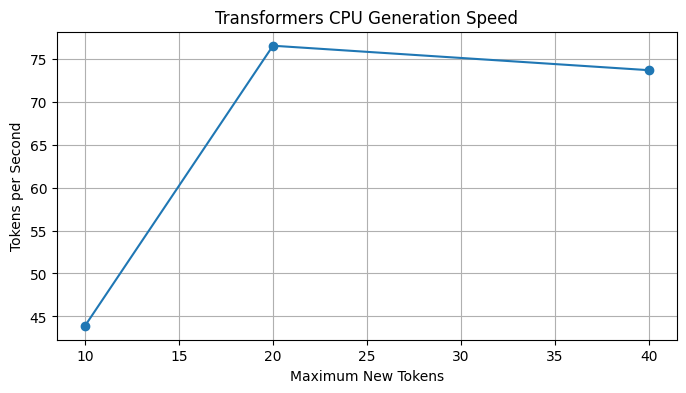

In [26]:
# 그래프 라이브러리 불러오기
import matplotlib.pyplot as plt

# 그래프 크기 설정
plt.figure(figsize=(8, 4))

# 최대 생성 토큰 수에 따른 속도 그래프
plt.plot(
    df["max_new_tokens"],
    df["tokens_per_second"],
    marker="o"
)

# 그래프 제목 설정
plt.title("Transformers CPU Generation Speed")

# 가로축 이름 설정
plt.xlabel("Maximum New Tokens")

# 세로축 이름 설정
plt.ylabel("Tokens per Second")

# 격자 표시
plt.grid(True)

# 그래프 출력
plt.show()

%pip install matplotlib pandas

실험 결과 CSV 저장

In [27]:
# 실험 결과를 CSV 파일로 저장
df.to_csv(
    "02_Transformers_CPU_Results.csv",
    index=False,
    encoding="utf-8-sig"
)

# 저장 완료 메시지 출력
print("CSV 파일 저장 완료")

CSV 파일 저장 완료


GitHub에 2회차 실습 업로드
Notebook을 Ctrl + S로 저장한 후 VS Code 터미널에서 실행한다.
# 2회차 Notebook과 CSV 파일 추가
git add 02_Transformers_CPU_Practice.ipynb 02_Transformers_CPU_Results.csv

# 2회차 실습 결과 기록
git commit -m "2회차 Transformers CPU 실습 완료"

# GitHub에 업로드
git push